=== ЭТАП 1: Генерация данных и обучение CNN ===


Генерация карт для обучения: 100%|██████████| 9/9 [00:00<00:00, 168.14it/s]


Эпоха 1, Loss: 486.5408
Эпоха 2, Loss: 91.7199
Эпоха 3, Loss: 81.8745
Эпоха 4, Loss: 79.6263
Эпоха 5, Loss: 76.9677
Эпоха 6, Loss: 73.3306
Эпоха 7, Loss: 67.5953
Эпоха 8, Loss: 60.6343
Эпоха 9, Loss: 54.6036
Эпоха 10, Loss: 49.5430
Эпоха 11, Loss: 44.9265
Эпоха 12, Loss: 41.6991
Эпоха 13, Loss: 38.8715
Эпоха 14, Loss: 36.6040
Эпоха 15, Loss: 34.6912
=== ЭТАП 2: Запуск основного эксперимента ===

Плотность: 10%


Тестирование 10%: 100%|██████████| 20/20 [00:02<00:00,  7.34it/s]



Плотность: 15%


...


Плотность: 45%


Тестирование 45%: 100%|██████████| 20/20 [00:00<00:00, 25.14it/s]



Плотность: 50%


Тестирование 50%: 100%|██████████| 20/20 [00:00<00:00, 28.14it/s]



=== ЭТАП 3: Статистический анализ ===
Плотность 10% | p-value (Time): 0.0000 | p-value (Nodes): 0.0000 | ΔTime: 134.09 мс
Плотность 15% | p-value (Time): 0.0000 | p-value (Nodes): 0.0000 | ΔTime: 106.86 мс
Плотность 20% | p-value (Time): 0.0000 | p-value (Nodes): 0.0000 | ΔTime: 88.20 мс
Плотность 25% | p-value (Time): 0.0000 | p-value (Nodes): 0.0000 | ΔTime: 70.34 мс
Плотность 30% | p-value (Time): 0.0000 | p-value (Nodes): 0.0001 | ΔTime: 57.48 мс
Плотность 35% | p-value (Time): 0.0000 | p-value (Nodes): 0.0000 | ΔTime: 49.90 мс
Плотность 40% | p-value (Time): 0.0000 | p-value (Nodes): 0.0001 | ΔTime: 41.99 мс
Плотность 45% | p-value (Time): 0.0000 | p-value (Nodes): 0.0001 | ΔTime: 38.36 мс
Плотность 50% | p-value (Time): 0.0000 | p-value (Nodes): 0.0001 | ΔTime: 34.31 мс


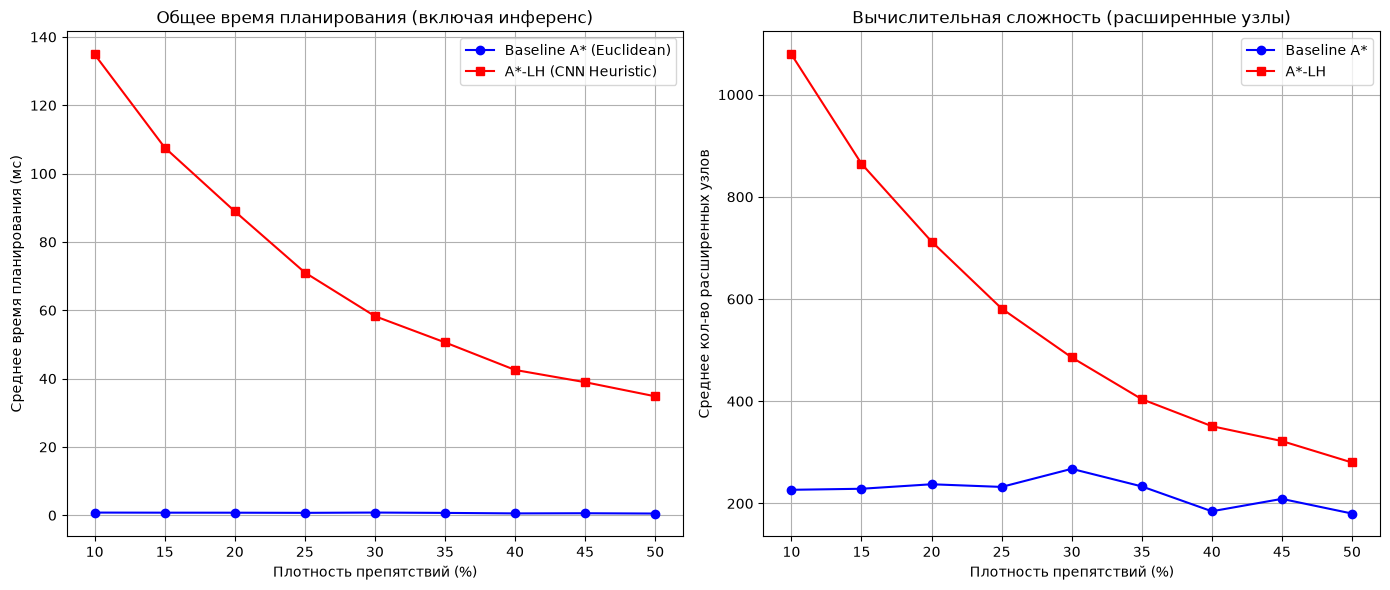

Графики сохранены в 'experiment_results.png'


In [ ]:
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import heapq
import time
import matplotlib.pyplot as plt
from scipy.stats import wilcoxon
from scipy.ndimage import binary_dilation
from collections import deque
from tqdm import tqdm
import warnings
warnings.filterwarnings('ignore')

# 1. КОНФИГУРАЦИЯ ЭКСПЕРИМЕНТА
GRID_SIZE = 30
PATCH_SIZE = 30
DENSITIES = np.arange(0.10, 0.55, 0.05) 
NUM_MAPS_PER_DENSITY = 20  
DEVICE = torch.device('cpu') 

# 2. ГЕНЕРАЦИЯ СРЕДЫ И ДАННЫХ
def generate_map(size, density):
    noise = np.random.rand(size, size) < (density * 0.5)
    seeds = np.random.rand(size, size) < (density * 0.1)
    clusters = binary_dilation(seeds, iterations=3)
    
    grid = noise | clusters
    grid[0, 0] = 0
    grid[size-1, size-1] = 0
    return grid.astype(np.uint8)

def is_reachable(grid, start, goal):
    size = grid.shape[0]
    visited = np.zeros((size, size), dtype=bool)
    queue = deque([start])
    visited[start] = True
    
    while queue:
        x, y = queue.popleft()
        if (x, y) == goal:
            return True
        for dx, dy in [(-1,0), (1,0), (0,-1), (0,1), (-1,-1), (-1,1), (1,-1), (1,1)]:
            nx, ny = x + dx, y + dy
            if 0 <= nx < size and 0 <= ny < size and not visited[nx, ny] and grid[nx, ny] == 0:
                visited[nx, ny] = True
                queue.append((nx, ny))
    return False

def compute_dijkstra_heuristic(grid, goal):
    """Вычисляет точную стоимость пути (h*) от всех узлов до цели (обратный Дейкстра)"""
    size = grid.shape[0]
    h_star = np.full((size, size), np.inf)
    h_star[goal] = 0
    pq = [(0, goal)]
    
    while pq:
        cost, (x, y) = heapq.heappop(pq)
        if cost > h_star[x, y]:
            continue
        for dx, dy in [(-1,0), (1,0), (0,-1), (0,1), (-1,-1), (-1,1), (1,-1), (1,1)]:
            nx, ny = x + dx, y + dy
            if 0 <= nx < size and 0 <= ny < size and grid[nx, ny] == 0:
                move_cost = 1.414 if (dx != 0 and dy != 0) else 1.0
                new_cost = cost + move_cost
                if new_cost < h_star[nx, ny]:
                    h_star[nx, ny] = new_cost
                    heapq.heappush(pq, (new_cost, (nx, ny)))
    return h_star

# 3. CNN МОДЕЛЬ И DATASET
class HeuristicDataset(Dataset):
    def __init__(self, maps, h_stars, patch_size):
        self.samples = []
        self.patch_size = patch_size
        pad = patch_size // 2
        
        for grid, h_star in zip(maps, h_stars):

            size = grid.shape[0]
            goal = (size-1, size-1)
            y_coords, x_coords = np.meshgrid(np.arange(size), np.arange(size), indexing='ij')
            dist_to_goal = np.sqrt((x_coords - goal[1])**2 + (y_coords - goal[0])**2)
            dist_to_goal = dist_to_goal / np.max(dist_to_goal) # Нормализация [0, 1]
            
            padded_grid = np.pad(grid, pad, mode='constant', constant_values=1)
            padded_dist = np.pad(dist_to_goal, pad, mode='constant', constant_values=1.0)
            
            for x in range(size):
                for y in range(size):
                    if grid[x, y] == 0 and h_star[x, y] != np.inf:
                        patch_obs = padded_grid[x:x+patch_size, y:y+patch_size]
                        patch_dist = padded_dist[x:x+patch_size, y:y+patch_size]

                        sample = np.stack([patch_obs, patch_dist], axis=0)
                        self.samples.append((sample, h_star[x, y]))

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        x, y = self.samples[idx]
        return torch.tensor(x, dtype=torch.float32), torch.tensor(y, dtype=torch.float32)

class LightweightCNN(nn.Module):
    def __init__(self):
        super(LightweightCNN, self).__init__()
        self.conv1 = nn.Conv2d(2, 16, kernel_size=3, padding=1)
        self.conv2 = nn.Conv2d(16, 32, kernel_size=3, padding=1)
        self.conv3 = nn.Conv2d(32, 16, kernel_size=3, padding=1)
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.fc = nn.Linear(16, 1)
        self.relu = nn.ReLU()

    def forward(self, x):
        x = self.relu(self.conv1(x))
        x = self.relu(self.conv2(x))
        x = self.relu(self.conv3(x))
        x = self.pool(x)
        x = torch.flatten(x, 1)
        x = self.fc(x)
        return x

# 4. АЛГОРИТМЫ ПОИСКА ПУТИ (A*)
def euclidean_heuristic(node, goal):
    return np.sqrt((node[0] - goal[0])**2 + (node[1] - goal[1])**2)

def astar_baseline(grid, start, goal):
    size = grid.shape[0]
    open_set = []
    heapq.heappush(open_set, (0, 0, start))
    g_score = {start: 0}
    came_from = {}
    nodes_expanded = 0
    
    start_time = time.perf_counter()
    while open_set:
        _, _, current = heapq.heappop(open_set)
        nodes_expanded += 1
        
        if current == goal:
            path_len = g_score[current]
            return nodes_expanded, path_len, time.perf_counter() - start_time
            
        for dx, dy in [(-1,0), (1,0), (0,-1), (0,1), (-1,-1), (-1,1), (1,-1), (1,1)]:
            nx, ny = current[0] + dx, current[1] + dy
            if 0 <= nx < size and 0 <= ny < size and grid[nx, ny] == 0:
                move_cost = 1.414 if (dx != 0 and dy != 0) else 1.0
                tentative_g = g_score[current] + move_cost
                
                if (nx, ny) not in g_score or tentative_g < g_score[(nx, ny)]:
                    came_from[(nx, ny)] = current
                    g_score[(nx, ny)] = tentative_g
                    f_score = tentative_g + euclidean_heuristic((nx, ny), goal)
                    heapq.heappush(open_set, (f_score, tentative_g, (nx, ny)))
    return nodes_expanded, -1, time.perf_counter() - start_time

def astar_learned(grid, start, goal, cnn_model, patch_size):
    """A* с обучаемой эвристикой (A*-LH)"""
    size = grid.shape[0]
    pad = patch_size // 2
    padded_grid = np.pad(grid, pad, mode='constant', constant_values=1)
    
    y_coords, x_coords = np.meshgrid(np.arange(size), np.arange(size), indexing='ij')
    dist_to_goal = np.sqrt((x_coords - goal[1])**2 + (y_coords - goal[0])**2)
    dist_to_goal = dist_to_goal / np.max(dist_to_goal)
    padded_dist = np.pad(dist_to_goal, pad, mode='constant', constant_values=1.0)

    open_set = []
    heapq.heappush(open_set, (0, 0, start))
    g_score = {start: 0}
    nodes_expanded = 0
    total_inf_time = 0
    
    start_time = time.perf_counter()
    while open_set:
        _, _, current = heapq.heappop(open_set)
        nodes_expanded += 1
        
        if current == goal:
            path_len = g_score[current]
            return nodes_expanded, path_len, time.perf_counter() - start_time, total_inf_time
            
        for dx, dy in [(-1,0), (1,0), (0,-1), (0,1), (-1,-1), (-1,1), (1,-1), (1,1)]:
            nx, ny = current[0] + dx, current[1] + dy
            if 0 <= nx < size and 0 <= ny < size and grid[nx, ny] == 0:
                move_cost = 1.414 if (dx != 0 and dy != 0) else 1.0
                tentative_g = g_score[current] + move_cost
                
                if (nx, ny) not in g_score or tentative_g < g_score[(nx, ny)]:
                    inf_start = time.perf_counter()
                    patch_obs = padded_grid[nx:nx+patch_size, ny:ny+patch_size]
                    patch_dist = padded_dist[nx:nx+patch_size, ny:ny+patch_size]
                    tensor_in = torch.tensor(np.stack([patch_obs, patch_dist], axis=0), 
                                             dtype=torch.float32).unsqueeze(0)
                    
                    with torch.no_grad():
                        h_cnn = cnn_model(tensor_in).item()
                    
                    total_inf_time += (time.perf_counter() - inf_start)
                    
                    h_eucl = euclidean_heuristic((nx, ny), goal)
                    h_used = max(h_cnn, h_eucl) 
                    
                    g_score[(nx, ny)] = tentative_g
                    f_score = tentative_g + h_used
                    heapq.heappush(open_set, (f_score, tentative_g, (nx, ny)))
                    
    return nodes_expanded, -1, time.perf_counter() - start_time, total_inf_time

# 5. ГЛАВНЫЙ ЦИКЛ ЭКСПЕРИМЕНТА
def run_experiment():
    print("=== ЭТАП 1: Генерация данных и обучение CNN ===")
    all_maps = []
    all_h_stars = []
    start = (0, 0)
    goal = (GRID_SIZE-1, GRID_SIZE-1)
    
    for d in tqdm(DENSITIES, desc="Генерация карт для обучения"):
        for _ in range(10):
            grid = generate_map(GRID_SIZE, d)
            if is_reachable(grid, start, goal):
                all_maps.append(grid)
                all_h_stars.append(compute_dijkstra_heuristic(grid, goal))
                
    dataset = HeuristicDataset(all_maps, all_h_stars, PATCH_SIZE)
    dataloader = DataLoader(dataset, batch_size=256, shuffle=True)
    
    cnn = LightweightCNN().to(DEVICE)
    optimizer = optim.Adam(cnn.parameters(), lr=1e-3)
    criterion = nn.MSELoss()
    
    cnn.train()
    for epoch in range(15): 
        total_loss = 0
        for inputs, targets in dataloader:
            inputs, targets = inputs.to(DEVICE), targets.to(DEVICE)
            optimizer.zero_grad()
            outputs = cnn(inputs).squeeze()
            loss = criterion(outputs, targets)
            loss.backward()
            optimizer.step()
            total_loss += loss.item()
        print(f"Эпоха {epoch+1}, Loss: {total_loss/len(dataloader):.4f}")
        
    cnn.eval()
    print("=== ЭТАП 2: Запуск основного эксперимента ===")
    
    results = {d: {'base_time': [], 'lh_time': [], 'base_nodes': [], 'lh_nodes': [], 'base_len': [], 'lh_len': []} for d in DENSITIES}
    
    for d in DENSITIES:
        print(f"\nПлотность: {d*100:.0f}%")
        valid_maps = []
        valid_h_stars = []
        
        while len(valid_maps) < NUM_MAPS_PER_DENSITY:
            grid = generate_map(GRID_SIZE, d)
            if is_reachable(grid, start, goal):
                valid_maps.append(grid)
                valid_h_stars.append(compute_dijkstra_heuristic(grid, goal))
                
        for grid in tqdm(valid_maps, desc=f"Тестирование {d*100:.0f}%"):
            # Baseline
            n_base, l_base, t_base = astar_baseline(grid, start, goal)
            results[d]['base_time'].append(t_base * 1000) # в мс
            results[d]['base_nodes'].append(n_base)
            results[d]['base_len'].append(l_base)
            
            # Proposed (A*-LH)
            n_lh, l_lh, t_total, t_inf = astar_learned(grid, start, goal, cnn, PATCH_SIZE)
            results[d]['lh_time'].append(t_total * 1000) # в мс
            results[d]['lh_nodes'].append(n_lh)
            results[d]['lh_len'].append(l_lh)
            
    return results

# 6. СТАТИСТИКА И ВИЗУАЛИЗАЦИЯ
def analyze_and_plot(results):
    print("\n ЭТАП 3: Статистический анализ ")
    densities = list(results.keys())
    p_values_time = []
    p_values_nodes = []
    
    for d in densities:
        _, p_time = wilcoxon(results[d]['base_time'], results[d]['lh_time'])
        _, p_nodes = wilcoxon(results[d]['base_nodes'], results[d]['lh_nodes'])
        p_values_time.append(p_time)
        p_values_nodes.append(p_nodes)
        
        mean_diff_time = np.mean(results[d]['lh_time']) - np.mean(results[d]['base_time'])
        print(f"Плотность {d*100:.0f}% | p-value (Time): {p_time:.4f} | p-value (Nodes): {p_nodes:.4f} | ΔTime: {mean_diff_time:.2f} мс")

    # Построение графиков
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))
    
    x = [d * 100 for d in densities]
    
    # График 1: Время планирования
    mean_base_t = [np.mean(results[d]['base_time']) for d in densities]
    mean_lh_t = [np.mean(results[d]['lh_time']) for d in densities]
    ax1.plot(x, mean_base_t, 'b-o', label='Baseline A* (Euclidean)')
    ax1.plot(x, mean_lh_t, 'r-s', label='A*-LH (CNN Heuristic)')
    ax1.set_xlabel('Плотность препятствий (%)')
    ax1.set_ylabel('Среднее время планирования (мс)')
    ax1.set_title('Общее время планирования (включая инференс)')
    ax1.legend()
    ax1.grid(True)
    
    # График 2: Количество расширенных узлов
    mean_base_n = [np.mean(results[d]['base_nodes']) for d in densities]
    mean_lh_n = [np.mean(results[d]['lh_nodes']) for d in densities]
    ax2.plot(x, mean_base_n, 'b-o', label='Baseline A*')
    ax2.plot(x, mean_lh_n, 'r-s', label='A*-LH')
    ax2.set_xlabel('Плотность препятствий (%)')
    ax2.set_ylabel('Среднее кол-во расширенных узлов')
    ax2.set_title('Вычислительная сложность (расширенные узлы)')
    ax2.legend()
    ax2.grid(True)
    
    plt.tight_layout()
    plt.savefig('experiment_results.png', dpi=300)
    plt.show()
    print("Графики сохранены в 'experiment_results.png'")

if __name__ == "__main__":
    exp_results = run_experiment()
    analyze_and_plot(exp_results)